<!-- CURRICULUM_HEADER_START -->
<div class="mh"><p class="mh-crumb"><a href="/series/earth-data/index.html">Earth Data in Python and R</a><span class="sep">·</span>Part 5 · Vector data</p><p class="mh-facts"><span class="lvl lvl-introductory">Introductory</span></p><p class="mh-assumes">Some programming in any language.</p></div>
<!-- CURRICULUM_HEADER_END -->

::: {.callout-note appearance="simple" icon=false}
## TL;DR

A GeoDataFrame is a pandas DataFrame with one extra column holding shapes, plus a coordinate reference system (CRS) that says what the numbers in those shapes mean. That one extra piece of state is where almost every beginner's error lives: computing areas in degrees, joining two layers in different CRSs, or losing leading zeros in an ID column so that nothing matches. This module loads the US Census county boundaries, measures them correctly in an equal-area projection (agreeing with the Census's own figures to $0.01\%$), joins a table of $\text{PM}_{2.5}$ concentrations onto them by county code, finds which county a point falls in, and dissolves counties into states. Afterwards you should be able to read any vector file, check its CRS before measuring anything, and choose between an attribute join and a spatial join.
:::

In [1]:
import sys
import warnings
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from shapely.geometry import Point

# fallcolor is the site's colour module at the repo root, not an installed package.
sys.path.insert(
    0,
    str(
        next(
            p
            for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "fallcolor.py").exists()
        )
    ),
)
import fallcolor

fallcolor.palette.use("default")
plt.rcParams["figure.dpi"] = 110
warnings.formatwarning = lambda msg, cat, *_, **__: (
    f"{cat.__name__}: {msg}\n"
)  # no file paths in output

DATA = "../pm25"  # the same Census boundaries the PM2.5 map uses

## A DataFrame with a geometry column

The county boundaries are the US Census Bureau's 2017 cartographic boundary file at 1:500,000 scale — a *shapefile*, which is really four or more files sharing a name (`.shp` for shapes, `.dbf` for attributes, `.shx` for an index, `.prj` for the CRS). `read_file` takes the `.shp` and finds the rest.

In [2]:
counties = gpd.read_file(f"{DATA}/cb_2017_us_county_500k/cb_2017_us_county_500k.shp")
print(type(counties).__name__, counties.shape)
counties.head(3)

GeoDataFrame (3233, 11)


,STATEFP,COUNTYFP,COUNTYNS,AFFGEOID,GEOID,NAME,LSAD,ALAND,AWATER,AgriRegion,geometry
0,01,005,00161528,0500000US01005,01005,Barbour,06,2292144656,50538698,EastUS,"POLYGON ((-85.74803 31.61918, -85.74544 31.618..."
1,01,023,00161537,0500000US01023,01023,Choctaw,06,2365869837,19144469,EastUS,"POLYGON ((-88.47323 31.89386, -88.46888 31.930..."
2,01,035,00161543,0500000US01035,01035,Conecuh,06,2201948618,6643480,EastUS,"POLYGON ((-87.4272 31.26436, -87.42551 31.2683..."


Everything except the last column is ordinary pandas: `STATEFP` and `COUNTYFP` are the state and county codes, `GEOID` is the two concatenated into the five-digit county FIPS code, `ALAND` and `AWATER` are the Census's own land and water areas in square metres. (`AgriRegion` was added to this copy of the file for the PM2.5 module; it is not part of the Census original.)

The `geometry` column is what makes it a GeoDataFrame. Each entry is a Shapely object — here a `Polygon`, or a `MultiPolygon` for counties made of several pieces, such as island counties.

In [3]:
counties.geom_type.value_counts()

Polygon         3043
MultiPolygon     190
Name: count, dtype: int64

## Coordinates mean nothing without a CRS

The numbers inside those polygons are only interpretable through the coordinate reference system. This file declares it in the `.prj`:

In [4]:
counties.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

EPSG:4269 is NAD83, a *geographic* CRS: coordinates are longitude and latitude in **degrees**. Degrees are angles, not lengths, so asking for an area in this CRS returns square degrees — and GeoPandas says so:

In [5]:
sq_degrees = counties.geometry.area

Square degrees are worse than an awkward unit: they are not even a consistent one. A degree of longitude spans about $111\text{ km}\times\cos\varphi$, where $\varphi$ is latitude, so it shrinks towards the poles. Compare a county in southern Florida with one in northern Maine, measured both ways. To get true areas we re-project to an **equal-area** projected CRS — EPSG:5070, the Albers projection the US government uses for the contiguous states — where coordinates are in metres.

In [6]:
pair = counties[
    ((counties.NAME == "Miami-Dade") & (counties.STATEFP == "12"))
    | ((counties.NAME == "Aroostook") & (counties.STATEFP == "23"))
].copy()
pair["lat"] = (
    pair.to_crs(5070).centroid.to_crs(4326).y
)  # centroid computed where it is valid
with warnings.catch_warnings():
    warnings.simplefilter(
        "ignore"
    )  # deliberately measuring in degrees; the warning was shown above
    pair["sq_degrees"] = pair.geometry.area
pair["km2"] = pair.to_crs(5070).geometry.area / 1e6
pair["km2_per_sq_degree"] = pair.km2 / pair.sq_degrees
pair[["NAME", "lat", "sq_degrees", "km2", "km2_per_sq_degree"]].round(2)

,NAME,lat,sq_degrees,km2,km2_per_sq_degree
359,Miami-Dade,25.61,0.47,5230.38,11127.18
741,Aroostook,46.66,2.08,17682.07,8507.78


A square degree is worth about $11{,}100\text{ km}^2$ in Florida and $8{,}500\text{ km}^2$ in Maine. The ratio between them is what $\cos\varphi$ predicts:

In [7]:
lat_s, lat_n = pair.sort_values("lat").lat
predicted = np.cos(np.radians(lat_s)) / np.cos(np.radians(lat_n))
observed = pair.sort_values("lat").km2_per_sq_degree.pipe(
    lambda s: s.iloc[0] / s.iloc[1]
)
print(f"cos-latitude predicts {predicted:.3f}; the projected areas give {observed:.3f}")

cos-latitude predicts 1.314; the projected areas give 1.308


Done properly, the projected areas are not approximately right; they are right. Over all 3,108 counties in the contiguous US, Albers areas agree with the Census's own published land-plus-water areas to a median of about one part in ten thousand:

In [8]:
NOT_CONUS = ["02", "15", "60", "66", "69", "72", "78"]  # AK, HI and the territories
conus = counties[~counties.STATEFP.isin(NOT_CONUS)]
km2 = conus.to_crs(5070).geometry.area / 1e6
census_km2 = (conus.ALAND + conus.AWATER) / 1e6
rel_err = (km2 - census_km2).abs() / census_km2
print(f"{len(conus)} counties; median relative difference {rel_err.median():.3%}")

3108 counties; median relative difference 0.011%


The rule is short: **check `.crs` before you measure anything**, and measure in a projected CRS chosen for the property you need — equal-area for areas and densities, a local projection for distances. Keep the geographic CRS for storage and for joining with other latitude–longitude data.

## Joining by attribute and by location

There are two ways to attach information to these counties, and they answer different questions.

### Attribute join: match on a shared key

An **attribute join** is an ordinary pandas `merge` on a column both tables share. The CDC's 2019 annual-mean $\text{PM}_{2.5}$ by county, exported from NIH HDPulse, carries the same five-digit FIPS code as `GEOID`. The export has four lines of title above the header and several lines of notes below the data, so we keep only rows whose code is five digits.

Read the code column naively and the join silently fails:

In [9]:
def load_pm25(**read_kw):
    raw = pd.read_csv(
        f"{DATA}/HDPulse_data_export.csv", skiprows=4, encoding="utf-8-sig", **read_kw
    )
    raw.columns = ["county", "fips", "pm25"]
    raw["pm25"] = pd.to_numeric(
        raw["pm25"], errors="coerce"
    )  # "data not available" -> NaN
    return raw


def match_rate(table):
    joined = counties.merge(
        table.assign(fips=table.fips.astype(str)),
        left_on="GEOID",
        right_on="fips",
        how="left",
    )
    return joined.pm25.notna().sum()


as_number = load_pm25()
print(
    "FIPS read as a number:",
    as_number.fips.head(3).tolist(),
    "->",
    match_rate(as_number),
    "counties matched",
)

FIPS read as a number: [0.0, 6071.0, 2090.0] -> 0 counties matched


Zero matches, and no error. pandas parsed `06071` (San Bernardino County, California) as the number `6071` — and, because the notes rows at the bottom are missing values, as the float `6071.0`. As text that is `"6071.0"`, which matches nothing in `GEOID`. The first row, the national total `00000`, became `0.0`. Codes that look like numbers are identifiers, and identifiers must be read as text:

In [10]:
pm25 = load_pm25(dtype={"FIPS": str})  # the column name as it appears in the file
pm25 = pm25[
    pm25.fips.str.fullmatch(r"\d{5}", na=False) & (pm25.fips != "00000")
]  # drop title, notes, US total
print(
    "FIPS read as text:",
    pm25.fips.head(3).tolist(),
    "->",
    match_rate(pm25),
    "of",
    len(counties),
    "counties matched",
)

counties_pm = counties.merge(
    pm25[["fips", "pm25"]], left_on="GEOID", right_on="fips", how="left"
)

FIPS read as text: ['06071', '02090', '42003'] -> 3114 of 3233 counties matched


The counties still unmatched are mainly Puerto Rico and the island territories, which the dataset does not cover, and a few Alaskan areas marked "data not available". **Always print a match count after a join**; a join that matches nothing looks exactly like one that matches everything until you plot it.

Plotting a column is one call. The full national map is in [Mapping PM2.5 by county](../pm25/plot_pm25_usa_by_county.ipynb); here is California alone, in a California-specific equal-area projection (EPSG:3310):

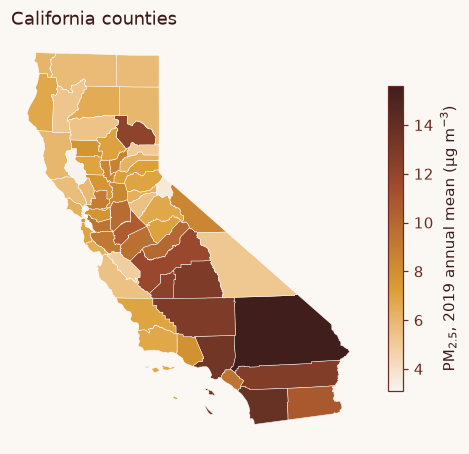

In [11]:
ca = counties_pm[counties_pm.STATEFP == "06"].to_crs(3310)

fig, ax = plt.subplots(figsize=(5.2, 6))
ca.plot(
    column="pm25",
    cmap="fall.ember",
    linewidth=0.3,
    edgecolor="white",
    legend=True,
    legend_kwds={"label": "PM$_{2.5}$, 2019 annual mean (µg m$^{-3}$)", "shrink": 0.6},
    ax=ax,
)
ax.set_axis_off()
ax.set_title("California counties", loc="left")
plt.show()

### Spatial join: match on geometry

A **spatial join** has no key column. It matches rows by how their shapes relate — which polygon contains which point, which lines cross which polygons. Four landmarks, given as longitude and latitude in WGS84 (EPSG:4326), the CRS of GPS:

In [12]:
places = gpd.GeoDataFrame(
    {
        "place": [
            "Mauna Loa Observatory",
            "Boston City Hall",
            "Space Needle, Seattle",
            "Colorado State Capitol",
        ]
    },
    geometry=[
        Point(-155.5763, 19.5362),
        Point(-71.0578, 42.3603),
        Point(-122.3493, 47.6205),
        Point(-104.9847, 39.7393),
    ],
    crs=4326,
)

found = gpd.sjoin(
    places.to_crs(counties.crs),
    counties[["NAME", "STATEFP", "geometry"]],
    how="left",
    predicate="within",
)
found[["place", "NAME", "STATEFP"]]

,place,NAME,STATEFP
0,Mauna Loa Observatory,Hawaii,15
1,Boston City Hall,Suffolk,25
2,"Space Needle, Seattle",King,53
3,Colorado State Capitol,Denver,08


Each landmark is placed in its county: Hawaii, Suffolk, King and Denver. Note `places.to_crs(counties.crs)` first: both layers must share a CRS before their geometries are compared, and GeoPandas warns if they do not. NAD83 and WGS84 differ by a metre or two in the contiguous US, which would not move these points across a county line, but the habit is the point — the same mismatch between a projected and a geographic layer would put every point in the wrong place, or nowhere.

## Dissolving counties into states

The inverse of splitting is **dissolving**: merge every geometry that shares a value into one, aggregating the attributes on the way. Counties to states is one call, and the boundaries between counties of the same state disappear:

3108 counties -> 49 polygons: the 48 contiguous states and DC


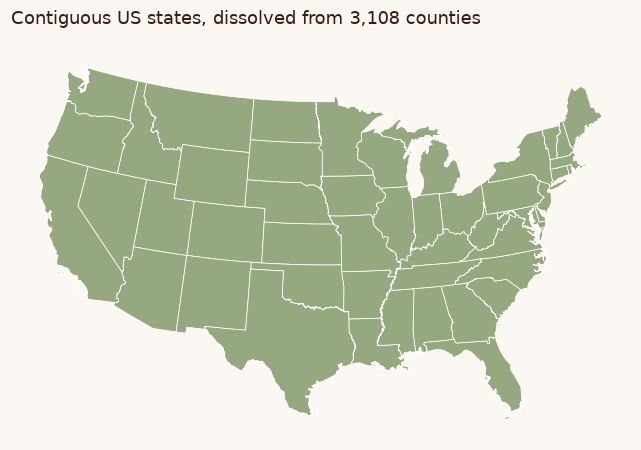

In [13]:
states = conus.dissolve(by="STATEFP", aggfunc={"ALAND": "sum", "AWATER": "sum"})
print(
    len(conus), "counties ->", len(states), "polygons: the 48 contiguous states and DC"
)

fig, ax = plt.subplots(figsize=(8, 4.6))
states.to_crs(5070).plot(
    ax=ax, color=fallcolor.palette["sage"].hex, edgecolor="white", linewidth=0.5
)
ax.set_axis_off()
ax.set_title("Contiguous US states, dissolved from 3,108 counties", loc="left")
plt.show()

## Key takeaways

- A GeoDataFrame is a DataFrame plus a `geometry` column of Shapely objects plus a `.crs`. Everything else is pandas.
- Check `.crs` before measuring. Areas and distances in a geographic CRS (degrees) are wrong, and wrong by an amount that changes with latitude ($\propto\cos\varphi$). Re-project to an equal-area CRS for areas.
- An **attribute join** is `merge` on a shared key. Read code columns such as FIPS as text, or leading zeros vanish and nothing matches — silently.
- A **spatial join** (`sjoin`) matches on geometry. Put both layers in the same CRS first.
- `dissolve` merges geometries that share a value and aggregates their attributes.
- After any join, print how many rows matched.

### Data and code

- **Boundaries**: US Census Bureau, 2017 cartographic boundary file, counties, 1:500,000. https://www.census.gov/geographies/mapping-files/time-series/geo/carto-boundary-file.html
- **PM$_{2.5}$**: CDC National Environmental Public Health Tracking Network, 2019 county annual mean, via NIH HDPulse (exported 6 December 2024). https://hdpulse.nimhd.nih.gov
- **Software**: [GeoPandas](https://geopandas.org) with Shapely and pyproj.

<!-- CURRICULUM_FOOTER_START -->
<div class="mf"><a class="mf-prev" href="/blogs/ms-buildings/index.html"><span>Previous</span>Downloading building footprints</a><a class="mf-up" href="/series/earth-data/index.html"><span>Series</span>Earth Data in Python and R</a><a class="mf-next" href="/blogs/pm25/plot_pm25_usa_by_county.html"><span>Next</span>Mapping PM2.5 by county</a></div>
<!-- CURRICULUM_FOOTER_END -->